# Do device types group by technology or by medical field?

**Question.** When medical device types are linked by how similar their adverse event reports read, do they group by the medical field they are used in, or by the technology they are built on?

**Hypothesis (H).** Device types group by technology more than by medical field. Example: a spinal cord stimulator's reports should read more like a pacemaker's (another implanted pulse generator, different field) than like a spinal implant's (same field, different technology).

**Network.**
- **Nodes** are product codes, the FDA's kinds of device. Each report's own product code is used.
- **Text** is the `event_description` of each report, embedded with `all-MiniLM-L6-v2`.
- Each code is represented by the average of its report embeddings.
- **Edges:** two codes are linked when the cosine similarity of their averages is at least 0.65. Codes with no link at that level are listed and left out of the tests.

**The two labels.** Neither one is used to build the network. They are only compared with it afterwards.

| label | source | values |
|---|---|---|
| medical field | FDA `advisory_committee` column | 16 fields, such as Cardiovascular or Neurology |
| technology | `labels/technology_labels.csv`, set by hand from each code's FDA name | 19 types, such as implanted pulse generator, stent, lens or lab test |

Technology describes what the device physically is and does, ignoring the body part. A pacemaker and a deep brain stimulator are both `implanted_pulse_generator`. The labels were drafted from device names only, never from the network, and should be reviewed by the group.

**Decision rules, fixed before looking at results:**

| | rule |
|---|---|
| technology beyond field | technology still groups links after its labels are shuffled **within** each field, so field alone cannot explain it (p < 0.01) |
| field beyond technology | the same test the other way round |
| **H supported** | technology assortativity is higher than field assortativity, technology matters beyond field, and both hold in the problem-term network and for cuts of 0.60, 0.65 and 0.70 |
| **H rejected** | field assortativity is at least as high as technology's, **and** technology does not matter beyond field |
| in between | partly supported |

**Check.** A second network is built from the FDA problem terms on the same reports (`product_problems` and `patient_problems`), with no embeddings. If both networks give the same answer, it does not depend on the embedding model.

Run `data_import.ipynb` first. The sample and the embeddings are cached in `data/processed/`, so only the first run is slow (about 20 minutes on a laptop CPU).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import normalized_mutual_info_score

PROCESSED_DIR = Path("data/processed")
SAMPLE_PATH = PROCESSED_DIR / "embedding_sample.csv.gz"
EMBEDDINGS_PATH = PROCESSED_DIR / "embedding_sample_minilm.npy"
TECHNOLOGY_PATH = Path("labels/technology_labels.csv")

SEED = 42
MIN_REPORTS = 30       # a code needs this many usable descriptions to be a node
MAX_REPORTS = 300      # at most this many descriptions per code are embedded
MIN_CHARS, MAX_CHARS = 40, 5_000
THRESHOLD = 0.65       # two codes are linked when their cosine similarity is at least this
ROBUSTNESS_THRESHOLDS = [0.60, 0.65, 0.70]
N_SHUFFLES = 1_000
LABELS = ["field", "technology"]

COMMITTEES = {
    "AN": "Anesthesiology", "CH": "Clinical chemistry", "CV": "Cardiovascular", "DE": "Dental",
    "EN": "Ear, nose, throat", "GU": "Gastro and urology", "HE": "Hematology", "HO": "General hospital",
    "IM": "Immunology", "MG": "Medical genetics", "MI": "Microbiology", "NE": "Neurology",
    "OB": "Obstetrics and gynecology", "OP": "Ophthalmic", "OR": "Orthopedic", "PA": "Pathology",
    "PM": "Physical medicine", "RA": "Radiology", "SU": "General and plastic surgery", "TX": "Clinical toxicology",
}

rng = np.random.default_rng(SEED)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## 1. Sample the reports

A report is usable if its text is not a repeat of an earlier report for the same device (`is_repeat_text`), and its description has 40 to 5,000 characters. Repeats are real reports with copied template text: they would pull a code's average towards one template. Shorter texts say little ("see narrative"), and longer ones are often registry extracts rather than one event.

Up to 300 usable reports are drawn at random per product code. More would mostly add insulin pumps and glucose monitors, without changing their average.

In [2]:
devices = pd.read_csv(PROCESSED_DIR / "pma_devices_2020_2025.csv", dtype=str)
reports = pd.read_csv(
    PROCESSED_DIR / "maude_reports.csv" if (PROCESSED_DIR / "maude_reports.csv").exists() else PROCESSED_DIR / "maude_reports.csv.gz",
    usecols=["mdr_report_key", "pma_number", "product_code", "event_type", "is_repeat_text", "text_chars",
             "product_problems", "patient_problems"],
    dtype=str,
)
reports["text_chars"] = reports["text_chars"].astype(int)

usable = reports[(reports["is_repeat_text"] == "False") & reports["text_chars"].between(MIN_CHARS, MAX_CHARS)]
per_code = usable["product_code"].value_counts()
kept_codes = per_code[per_code >= MIN_REPORTS].index

print(f"Usable reports: {len(usable):,} of {len(reports):,}")
print(f"Product codes: {per_code.size}, of which {kept_codes.size} have at least {MIN_REPORTS} usable reports")
print(f"Those codes cover {usable['product_code'].isin(kept_codes).mean():.1%} of usable reports")

Usable reports: 1,875,417 of 2,422,364
Product codes: 402, of which 201 have at least 30 usable reports
Those codes cover 99.9% of usable reports


In [3]:
if SAMPLE_PATH.exists():
    sample = pd.read_csv(SAMPLE_PATH, dtype=str)
else:
    sample = (
        usable[usable["product_code"].isin(kept_codes)]
        .sample(frac=1, random_state=SEED)
        .groupby("product_code").head(MAX_REPORTS)
        .drop(columns=["is_repeat_text"])
    )
    # The text file is 4 GB, so it is read in chunks and only sampled reports are kept.
    text_path = PROCESSED_DIR / "maude_text.csv"
    if not text_path.exists():
        text_path = PROCESSED_DIR / "maude_text.csv.gz"
    wanted = set(sample["mdr_report_key"])
    texts = []
    for chunk in pd.read_csv(text_path, usecols=["mdr_report_key", "event_description"], dtype=str, chunksize=200_000):
        texts.append(chunk[chunk["mdr_report_key"].isin(wanted)])
    texts = pd.concat(texts)
    sample = sample.merge(texts, on="mdr_report_key", how="inner").sort_values(["product_code", "mdr_report_key"])
    sample.to_csv(SAMPLE_PATH, index=False)

sample = sample.reset_index(drop=True)
assert sample["event_description"].notna().all()
assert sample["mdr_report_key"].is_unique
print(f"Sample: {len(sample):,} reports from {sample['product_code'].nunique()} product codes "
      f"({len(sample) / usable['product_code'].isin(kept_codes).sum():.1%} of their usable reports)")
sample["product_code"].value_counts().describe().round(0).to_frame("reports per code")

Sample: 48,450 reports from 201 product codes (2.6% of their usable reports)


,reports per code
count,201.0
mean,241.0
std,94.0
min,30.0
25%,178.0
50%,300.0
75%,300.0
max,300.0


### Labels for each code

**Medical field.** The field FDA lists for the code in its approval records (`advisory_committee`). If a code is missing there, the most common field of the devices it was reported under is used.

**Technology.** Read from `labels/technology_labels.csv`. Every code in the sample must have one.

In [4]:
records = pd.read_csv(PROCESSED_DIR / "pma_records.csv", dtype=str, usecols=["product_code", "advisory_committee"]).dropna()
field_from_records = records.groupby("product_code")["advisory_committee"].agg(lambda s: s.mode()[0])
sample["device_field"] = sample["pma_number"].map(devices.set_index("pma_number")["advisory_committee"])
field_from_devices = sample.groupby("product_code")["device_field"].agg(lambda s: s.mode()[0])
technology = pd.read_csv(TECHNOLOGY_PATH, dtype=str).set_index("product_code")

codes = sample.groupby("product_code").agg(n_reports=("mdr_report_key", "size"))
codes["field"] = field_from_records.reindex(codes.index).fillna(field_from_devices).map(COMMITTEES)
codes["technology"] = technology["technology"].reindex(codes.index)
codes["name"] = technology["fda_name"].reindex(codes.index)
assert codes["technology"].notna().all(), f"codes without a technology label: {list(codes.index[codes['technology'].isna()])}"
assert codes["field"].notna().all()

print(f"Field taken from approval records for {codes.index.isin(field_from_records.index).mean():.0%} of codes")
print(f"{codes['field'].nunique()} fields and {codes['technology'].nunique()} technologies")
print(f"Agreement between the two labels (NMI, 1 = same grouping): "
      f"{normalized_mutual_info_score(codes['field'], codes['technology']):.2f}")
pd.crosstab(codes["technology"], codes["field"])

Field taken from approval records for 89% of codes
16 fields and 19 technologies
Agreement between the two labels (NMI, 1 = same grouping): 0.58


field,Anesthesiology,Cardiovascular,Clinical chemistry,Dental,"Ear, nose, throat",Gastro and urology,General and plastic surgery,General hospital,Immunology,Microbiology,Neurology,Obstetrics and gynecology,Ophthalmic,Orthopedic,Pathology,Radiology
technology,,,,,,,,,,,,,,,,
blood_pump_or_life_support,1,4,0,0,0,2,0,0,0,0,0,0,0,0,0,0
body_sensor,0,1,8,0,0,0,0,0,0,0,0,0,0,0,0,0
catheter_or_procedure_tool,0,16,0,0,0,0,0,0,0,0,0,0,0,0,0,0
energy_based_therapy,0,1,0,0,0,0,0,0,0,0,1,1,1,0,0,0
external_electrical_device,0,3,0,0,0,0,0,0,0,0,1,0,0,1,0,0
imaging,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,2
implanted_lead,0,4,0,0,0,0,0,0,0,0,0,0,0,0,0,0
implanted_pulse_generator,1,12,0,0,5,1,0,0,0,0,11,0,0,0,0,0
infusion_pump,0,0,6,0,0,0,0,1,0,0,0,0,0,0,0,0


The table shows how much the two labels overlap. Some technologies sit in one field (all lenses are ophthalmic), others span several (implanted pulse generators are in cardiovascular, neurology, ear-nose-throat, urology and anesthesiology). Only the technologies that span fields can tell the two apart, which is why the tests below shuffle one label *within* the other.

## 2. Embed the descriptions

`all-MiniLM-L6-v2` is a small, widely used sentence model. Texts are cut at 128 tokens, which keeps the start of each description, where the event is usually stated. Embeddings are normalised, so a dot product is a cosine similarity.

In [5]:
if EMBEDDINGS_PATH.exists():
    embeddings = np.load(EMBEDDINGS_PATH)
else:
    from sentence_transformers import SentenceTransformer

    model = SentenceTransformer("all-MiniLM-L6-v2", device="cpu")
    model.max_seq_length = 128
    embeddings = model.encode(
        sample["event_description"].tolist(), batch_size=64, normalize_embeddings=True, show_progress_bar=False
    ).astype(np.float32)
    np.save(EMBEDDINGS_PATH, embeddings)

assert len(embeddings) == len(sample), "embeddings do not match the sample; delete both cache files and rerun"
embeddings.shape

(48450, 384)

## 3. Build the network

Each code's vector is the average of its report embeddings, normalised again. Two codes are linked when their cosine similarity is at least 0.65, and the link is weighted by that similarity.

Keeping every pair would give a complete network: all codes are a little similar, so the structure would be hidden. A fixed cut means a link stands for the same level of similarity everywhere, so the number of links a code has carries meaning. The price is that unusual codes may get no link at all. They are listed below and left out of the tests. Section 7 checks that the choice of 0.65 does not drive the result.

In [6]:
def centroids(vectors, groups, order):
    frame = pd.DataFrame(vectors).groupby(groups.values).mean().loc[order]
    matrix = frame.to_numpy()
    return matrix / np.linalg.norm(matrix, axis=1, keepdims=True)


def knn_graph(similarity, labels, k):
    graph = nx.Graph()
    graph.add_nodes_from(labels)
    sim = similarity.copy()
    np.fill_diagonal(sim, -np.inf)
    for i, row in enumerate(sim):
        for j in np.argsort(row)[-k:]:
            graph.add_edge(labels[i], labels[j], weight=float(similarity[i, j]))
    return graph


def threshold_graph(similarity, labels, threshold):
    # Codes with no link are left out, so every node has at least one edge.
    graph = nx.Graph()
    a, b = np.triu_indices(len(labels), 1)
    keep = similarity[a, b] >= threshold
    graph.add_weighted_edges_from(zip(labels[a[keep]], labels[b[keep]], similarity[a, b][keep]))
    return graph


def matched_graph(similarity, labels, n_edges):
    # Cut at whatever similarity gives n_edges links, so two networks on different scales have the same density.
    a, b = np.triu_indices(len(labels), 1)
    return threshold_graph(similarity, labels, np.sort(similarity[a, b])[-n_edges])


order = codes.index.to_numpy()
text_vectors = centroids(embeddings, sample["product_code"], order)
text_sim = text_vectors @ text_vectors.T
G = threshold_graph(text_sim, order, THRESHOLD)

upper = text_sim[np.triu_indices(len(order), 1)]
degree = pd.Series(dict(G.degree))
print(f"Nodes: {G.number_of_nodes()} of {len(order)} codes, edges: {G.number_of_edges()}, "
      f"connected parts: {nx.number_connected_components(G)} (largest has {len(max(nx.connected_components(G), key=len))} codes)")
print(f"Cosine similarity between code averages: median {np.median(upper):.2f}, range {upper.min():.2f}-{upper.max():.2f}")
print(f"Links per code: median {degree.median():.0f}, max {degree.max()} ({degree.idxmax()}: {codes.at[degree.idxmax(), 'name']})")

isolated = codes.loc[~codes.index.isin(G.nodes), ["field", "technology", "name", "n_reports"]]
print(f"\nCodes with no link at {THRESHOLD} (left out of the tests): {len(isolated)}")
isolated

Nodes: 195 of 201 codes, edges: 1709, connected parts: 4 (largest has 186 codes)
Cosine similarity between code averages: median 0.45, range 0.07-1.00
Links per code: median 16, max 48 (DSQ: Ventricular (assist) bypass)

Codes with no link at 0.65 (left out of the tests): 6


,field,technology,name,n_reports
product_code,,,,
LNR,Gastro and urology,blood_pump_or_life_support,"System, photopheresis, extracorporeal",300
LOK,Immunology,lab_test,"KIT, TEST, ALPHA-FETOPROTEIN FOR NEURAL TUBE D...",54
NJK,Anesthesiology,valve_or_valve_repair,"Valve, pulmonary",300
NZK,Neurology,external_electrical_device,"Stimulator, low electric field, tumor treatment",300
OWD,Pathology,lab_test,Somatic gene mutation detection system,111
POH,Neurology,energy_based_therapy,MR-guided focused ultrasound system,176


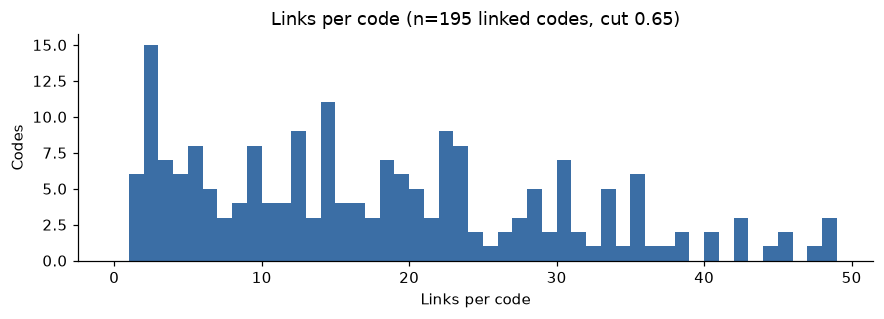

In [7]:
fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(degree, bins=range(0, degree.max() + 2), color="#3b6ea5")
ax.set(xlabel="Links per code", ylabel="Codes", title=f"Links per code (n={G.number_of_nodes()} linked codes, cut {THRESHOLD})")
plt.tight_layout()

## 4. Do links follow field or technology?

**Assortativity** measures whether links join codes with the same label: 0 means no more than chance, 1 means every link stays within a label.

Two kinds of shuffle give the chance level, always keeping the network fixed:
- **Free shuffle:** labels are shuffled across all codes. Does the label matter at all?
- **Shuffle within the other label:** technology labels are shuffled only among codes of the same field (and the other way round). This keeps everything field explains, so if technology still beats the shuffles, it adds something field does not.

In [8]:
def assortativity(graph, labels):
    nx.set_node_attributes(graph, labels.to_dict(), "label")
    return nx.attribute_assortativity_coefficient(graph, "label")


def shuffled(labels, within=None):
    if within is None:
        return pd.Series(rng.permutation(labels.to_numpy()), index=labels.index)
    out = labels.copy()
    for _, idx in labels.groupby(within).groups.items():
        out.loc[idx] = rng.permutation(labels.loc[idx].to_numpy())
    return out


def label_test(graph, label, within=None, n_shuffles=N_SHUFFLES):
    labels = codes[label].reindex(list(graph.nodes))
    groups = None if within is None else codes[within].reindex(labels.index)
    observed = assortativity(graph, labels)
    null = np.array([assortativity(graph, shuffled(labels, groups)) for _ in range(n_shuffles)])
    return {
        "assortativity": observed,
        "null mean": null.mean(),
        "null 99th percentile": np.quantile(null, 0.99),
        "p (one-sided)": (np.sum(null >= observed) + 1) / (n_shuffles + 1),
    }


def label_tests(graph, n_shuffles=N_SHUFFLES):
    return pd.DataFrame({
        "field": label_test(graph, "field", n_shuffles=n_shuffles),
        "technology": label_test(graph, "technology", n_shuffles=n_shuffles),
        "technology, shuffled within field": label_test(graph, "technology", within="field", n_shuffles=n_shuffles),
        "field, shuffled within technology": label_test(graph, "field", within="technology", n_shuffles=n_shuffles),
    }).T


def share_within(graph, label):
    return np.mean([codes.at[u, label] == codes.at[v, label] for u, v in graph.edges])


tests = label_tests(G)
for label in LABELS:
    print(f"Links within the same {label}: {share_within(G, label):.0%}")
tests.round(3)

Links within the same field: 60%
Links within the same technology: 50%


,assortativity,null mean,null 99th percentile,p (one-sided)
field,0.462,-0.007,0.015,0.001
technology,0.417,-0.008,0.007,0.001
"technology, shuffled within field",0.417,0.160,0.187,0.001
"field, shuffled within technology",0.462,0.291,0.338,0.001


The same question over every pair of codes, not only linked ones: the average similarity, split by whether the two codes share a field and whether they share a technology. The key cell is **different field, same technology**: if it is higher than **same field, different technology**, technology matters more.

In [9]:
i, j = np.triu_indices(len(order), 1)
pairs = pd.DataFrame({
    "similarity": text_sim[i, j],
    "same field": np.where(codes["field"].to_numpy()[i] == codes["field"].to_numpy()[j], "same field", "different field"),
    "same technology": np.where(codes["technology"].to_numpy()[i] == codes["technology"].to_numpy()[j], "same technology", "different technology"),
})


def pair_table(pairs):
    table = pairs.groupby(["same field", "same technology"])["similarity"].agg(["mean", "size"]).round(3)
    return table.rename(columns={"mean": "mean similarity", "size": "pairs"})


pair_table(pairs)

mean similarity  pairs
same field      same technology                             
different field different technology            0.426  15596
                same technology                 0.630    661
same field      different technology            0.522   2966
                same technology                 0.719    877

The same split for the network's links. **Link rate** is the share of possible pairs of that kind that became a link, counting only codes in the network. It corrects for how many pairs of each kind exist: there are far more same-field pairs to choose from than different-field, same-technology pairs.

In [10]:
def link_table(graph, pairs):
    edges = set(map(frozenset, graph.edges))
    in_graph = np.isin(order[i], list(graph.nodes)) & np.isin(order[j], list(graph.nodes))
    is_link = np.array([frozenset((order[a], order[b])) in edges for a, b in zip(i, j)])
    table = pairs.assign(link=is_link)[in_graph].groupby(["same field", "same technology"])["link"].agg(["sum", "size", "mean"])
    table.columns = ["links", "possible pairs", "link rate"]
    table["share of links"] = table["links"] / table["links"].sum()
    return table.round(3)


link_table(G, pairs)

links  possible pairs  link rate  \
same field      same technology                                          
different field different technology    392           14502      0.027   
                same technology         293             624      0.470   
same field      different technology    467            2918      0.160   
                same technology         557             871      0.639   

                                      share of links  
same field      same technology                       
different field different technology           0.229  
                same technology                0.171  
same field      different technology           0.273  
                same technology                0.326

## 5. Communities

Communities are found with the Louvain method. It is random, so it runs with 20 seeds and keeps the split with the highest modularity. The agreement between seeds (NMI, 1 = identical) shows how stable the split is.

NMI with each label says how closely the communities match it, compared with the same score after shuffling the labels.

In [11]:
def best_partition(graph, seeds=range(20)):
    runs = [nx.community.louvain_communities(graph, weight="weight", seed=s) for s in seeds]
    scores = [nx.community.modularity(graph, run, weight="weight") for run in runs]
    as_labels = [pd.Series({n: c for c, members in enumerate(run) for n in members}) for run in runs]
    best = int(np.argmax(scores))
    nodes = list(graph.nodes)
    stability = np.mean([normalized_mutual_info_score(as_labels[best][nodes], other[nodes]) for other in as_labels])
    return as_labels[best], scores[best], stability


def nmi_table(partition, n_shuffles=N_SHUFFLES):
    rows = {}
    nodes = partition.index
    for label in LABELS:
        labels = codes[label][nodes]
        observed = normalized_mutual_info_score(labels, partition[nodes])
        null = [normalized_mutual_info_score(rng.permutation(labels.to_numpy()), partition[nodes]) for _ in range(n_shuffles)]
        rows[label] = {"NMI with communities": observed, "shuffled labels": float(np.mean(null))}
    return pd.DataFrame(rows).T


partition, modularity, stability = best_partition(G)
codes["community"] = partition.reindex(codes.index)
print(f"{partition.nunique()} communities, modularity {modularity:.2f}, agreement between seeds (NMI) {stability:.2f}")
nmi_table(partition).round(2)

10 communities, modularity 0.61, agreement between seeds (NMI) 0.96


,NMI with communities,shuffled labels
field,0.63,0.14
technology,0.65,0.16


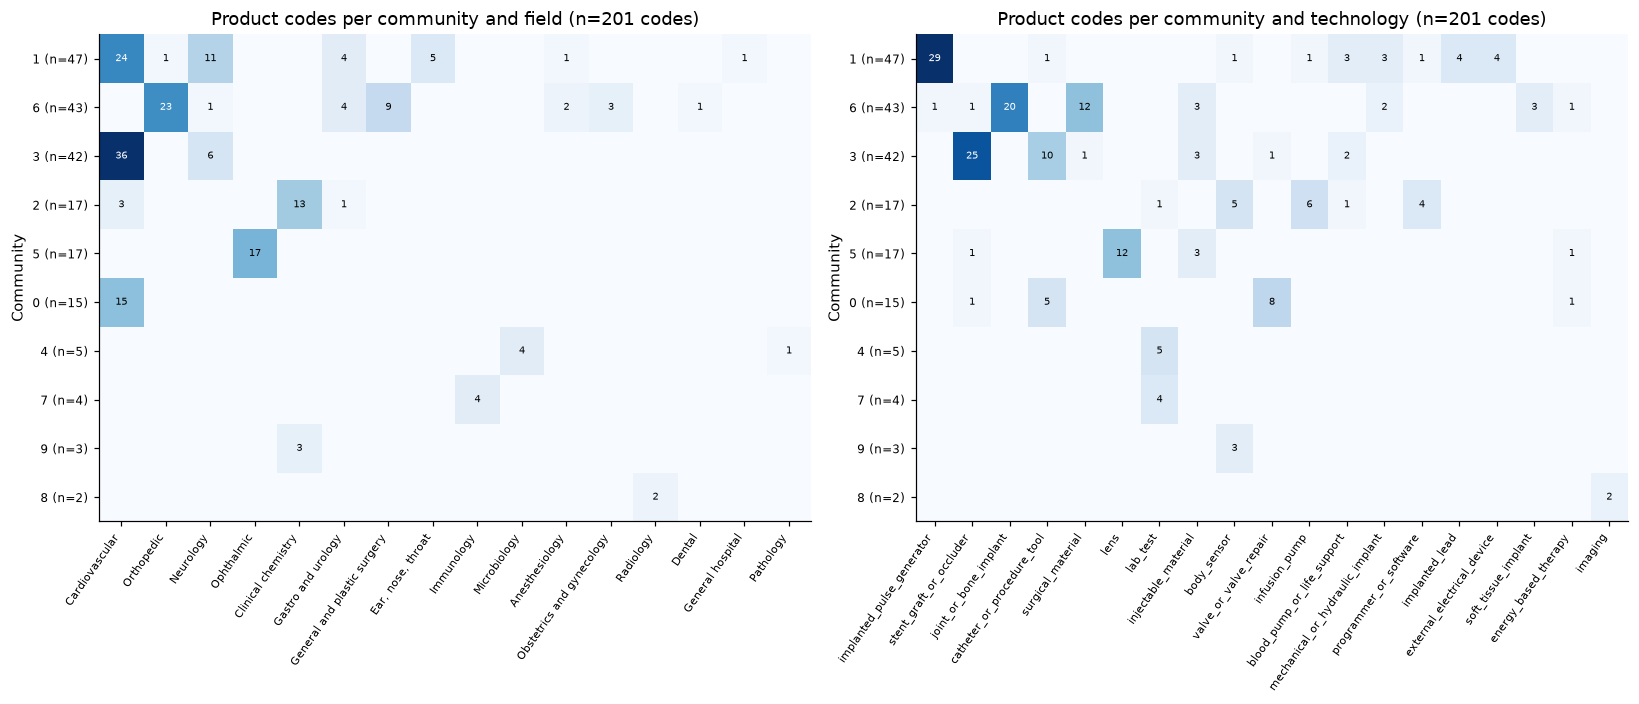

In [12]:
def heatmap(ax, table, title):
    ax.imshow(table.to_numpy(), cmap="Blues", aspect="auto")
    ax.set_xticks(range(table.shape[1]), table.columns, rotation=55, ha="right", fontsize=7)
    ax.set_yticks(range(len(table)), [f"{int(c)} (n={n})" for c, n in table.sum(axis=1).items()], fontsize=8)
    for (r, c), v in np.ndenumerate(table.to_numpy()):
        if v:
            ax.text(c, r, v, ha="center", va="center", fontsize=6.5, color="white" if v > table.to_numpy().max() / 2 else "black")
    ax.set(title=title, ylabel="Community")


size_order = codes["community"].value_counts().index
fig, axes = plt.subplots(1, 2, figsize=(15, 0.35 * len(size_order) + 3))
for ax, label in zip(axes, LABELS):
    table = pd.crosstab(codes["community"], codes[label]).loc[size_order]
    table = table[table.sum().sort_values(ascending=False).index]
    heatmap(ax, table, f"Product codes per community and {label} (n={len(codes)} codes)")
plt.tight_layout()

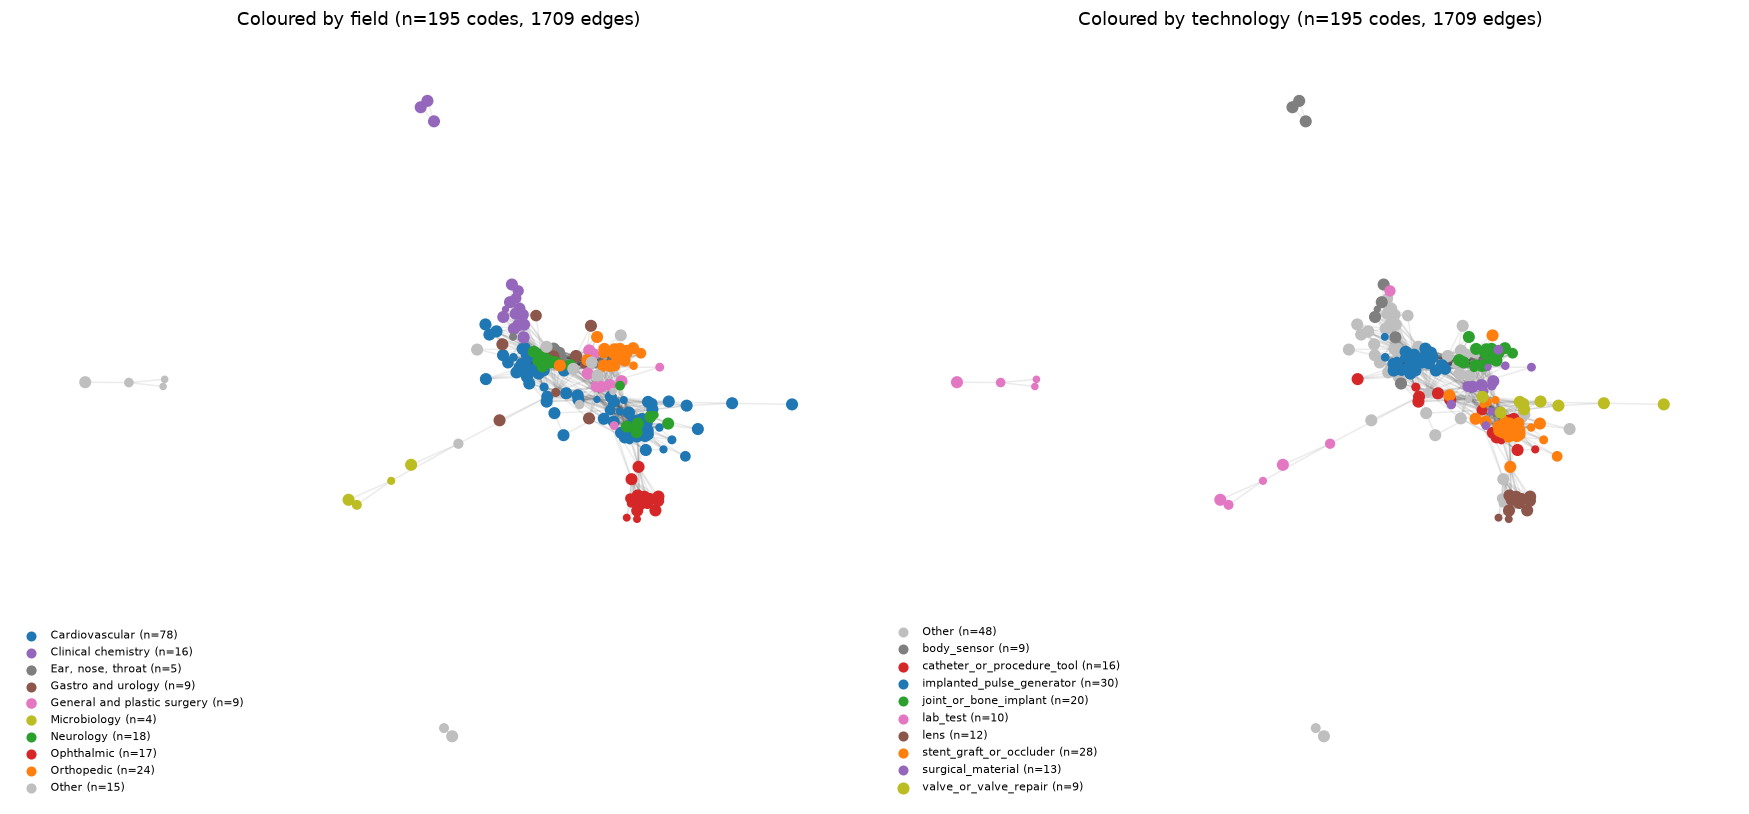

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7.5))
position = nx.spring_layout(G, weight="weight", seed=SEED)
linked = codes.loc[list(G.nodes)]
for ax, label in zip(axes, LABELS):
    shown = linked[label].value_counts().index[:9]
    palette = dict(zip(shown, plt.cm.tab10.colors))
    nx.draw_networkx_edges(G, position, alpha=0.08, ax=ax)
    for value, group in linked.groupby(linked[label].where(linked[label].isin(shown), "Other")):
        nx.draw_networkx_nodes(
            G, position, nodelist=list(group.index), node_size=10 + group["n_reports"] / 8,
            node_color=[palette.get(value, (0.75, 0.75, 0.75))], label=f"{value} (n={len(group)})", ax=ax,
        )
    ax.legend(fontsize=7, loc="lower left", frameon=False)
    ax.set(title=f"Coloured by {label} (n={G.number_of_nodes()} codes, {G.number_of_edges()} edges)")
    ax.axis("off")
plt.tight_layout()

### What each community is about

For each community: its largest codes, the words that set its descriptions apart (TF-IDF over all communities), and the FDA problem terms most over-represented in it (lift = share in the community ÷ share overall, among terms in at least 5% of its reports).

In [14]:
sample["community"] = sample["product_code"].map(codes["community"])
community_text = sample.groupby("community")["event_description"].apply(" ".join)
tfidf = TfidfVectorizer(stop_words="english", min_df=2, max_df=0.5, token_pattern=r"(?u)\b[a-zA-Z]{3,}\b", sublinear_tf=True)
weights = tfidf.fit_transform(community_text)
vocabulary = np.array(tfidf.get_feature_names_out())


def problem_terms(frame):
    terms = (frame["product_problems"].fillna("") + "; " + frame["patient_problems"].fillna("")).str.split("; ")
    return terms.explode().str.strip().loc[lambda s: s != ""]


all_terms = problem_terms(sample).value_counts(normalize=True)

for c in size_order:
    members = codes[codes["community"] == c].sort_values("n_reports", ascending=False)
    in_community = sample[sample["community"] == c]
    counts = problem_terms(in_community).value_counts()
    share = counts / len(in_community)
    lift = (counts / counts.sum() / all_terms.reindex(counts.index)).where(share >= 0.05).dropna().nlargest(5)
    words = vocabulary[np.argsort(weights[community_text.index.get_loc(c)].toarray().ravel())[-10:][::-1]]

    print(f"=== Community {int(c)}: {len(members)} codes, {members['field'].nunique()} fields, {members['technology'].nunique()} technologies")
    for code_, row in members.head(8).iterrows():
        print(f"   {code_}  {row['field']:<28} {row['technology']:<32} {str(row['name'])[:45]}")
    print(f"   distinctive words: {', '.join(words)}")
    print(f"   over-represented problems: {'; '.join(f'{t} (x{v:.1f})' for t, v in lift.items())}\n")

=== Community 1: 47 codes, 7 fields, 9 technologies
   MKJ  Cardiovascular               external_electrical_device       Automated external defibrillators (non-wearab
   NHL  Neurology                    implanted_pulse_generator        Stimulator, electrical, implanted, for parkin
   MHY  Neurology                    implanted_pulse_generator        Stimulator, electrical, implanted, for parkin
   DSQ  Cardiovascular               blood_pump_or_life_support       Ventricular (assist) bypass
   MOM  Cardiovascular               body_sensor                      System, hemodynamic, implantable
   MPV  Ear, nose, throat            implanted_pulse_generator        Implant, hearing, active, middle ear, partial
   MRM  Cardiovascular               implanted_pulse_generator        DEFIBRILLATOR, IMPLANTABLE, DUAL-CHAMBER
   MUZ  Neurology                    implanted_pulse_generator        Stimulator, autonomic nerve, implanted (depre
   distinctive words: ins, electrodes, ipg, ipp, spectra

## 6. Check: the problem-term network

The same network is built without embeddings. Each code becomes a TF-IDF vector of the FDA problem terms on its sampled reports. These similarities are on a different scale, so a cut of 0.65 would mean something else here. Instead the cut is set to give the same number of links as the text network.

- **Mantel test:** do the two similarity matrices agree over all pairs of codes? The null shuffles the codes of one matrix 1,000 times.
- **The same label tests** as in section 4, so the conclusions can be compared directly.

In [15]:
report_terms = problem_terms(sample)
term_docs = report_terms.groupby(sample.loc[report_terms.index, "product_code"]).agg("|".join).loc[order]
term_vectorizer = TfidfVectorizer(tokenizer=lambda s: s.split("|"), token_pattern=None, lowercase=False, sublinear_tf=True)
term_vectors = term_vectorizer.fit_transform(term_docs)
term_sim = (term_vectors @ term_vectors.T).toarray()
G_terms = matched_graph(term_sim, order, G.number_of_edges())
print(f"Problem-term network: {G_terms.number_of_nodes()} linked codes, {G_terms.number_of_edges()} edges")

a, b = text_sim[i, j], term_sim[i, j]
mantel = np.corrcoef(a, b)[0, 1]
mantel_null = []
for _ in range(N_SHUFFLES):
    p = rng.permutation(len(order))
    mantel_null.append(np.corrcoef(a, term_sim[p][:, p][i, j])[0, 1])
mantel_null = np.array(mantel_null)
print(f"Mantel correlation between text and problem-term similarity: {mantel:.2f} "
      f"(shuffled: mean {mantel_null.mean():.2f}, max {mantel_null.max():.2f}, p = {(np.sum(mantel_null >= mantel) + 1) / (N_SHUFFLES + 1):.3f})")
shared_edges = len(set(map(frozenset, G.edges)) & set(map(frozenset, G_terms.edges)))
print(f"Edges in both networks: {shared_edges} of {G.number_of_edges()} text edges")

term_partition, term_modularity, term_stability = best_partition(G_terms)
print(f"Problem-term network: {term_partition.nunique()} communities, modularity {term_modularity:.2f}, agreement between seeds {term_stability:.2f}")
both = partition.index.intersection(term_partition.index)
print(f"Agreement between the two community splits (NMI, {len(both)} codes in both): "
      f"{normalized_mutual_info_score(partition[both], term_partition[both]):.2f}")
for label in LABELS:
    print(f"Links within the same {label}: {share_within(G_terms, label):.0%}")
print()
print(nmi_table(term_partition).round(2).to_string())

term_tests = label_tests(G_terms)
term_pairs = pairs.assign(similarity=term_sim[i, j])
display(term_tests.round(3))
display(pair_table(term_pairs))
link_table(G_terms, term_pairs)

Problem-term network: 199 linked codes, 1709 edges


Mantel correlation between text and problem-term similarity: 0.68 (shuffled: mean -0.00, max 0.06, p = 0.001)
Edges in both networks: 966 of 1709 text edges


Problem-term network: 10 communities, modularity 0.64, agreement between seeds 0.96
Agreement between the two community splits (NMI, 193 codes in both): 0.73
Links within the same field: 72%
Links within the same technology: 49%



            NMI with communities  shuffled labels
field                       0.65             0.13
technology                  0.65             0.16


,assortativity,null mean,null 99th percentile,p (one-sided)
field,0.578,-0.007,0.014,0.001
technology,0.413,-0.007,0.010,0.001
"technology, shuffled within field",0.413,0.170,0.194,0.001
"field, shuffled within technology",0.578,0.358,0.409,0.001


mean similarity  pairs
same field      same technology                             
different field different technology            0.084  15596
                same technology                 0.198    661
same field      different technology            0.160   2966
                same technology                 0.370    877

links  possible pairs  link rate  \
same field      same technology                                          
different field different technology    267           15293      0.017   
                same technology         218             646      0.337   
same field      different technology    607            2889      0.210   
                same technology         617             873      0.707   

                                      share of links  
same field      same technology                       
different field different technology           0.156  
                same technology                0.128  
same field      different technology           0.355  
                same technology                0.361

## 7. Robustness: where the cut is

The cut of 0.65 is a choice, so the main numbers are recomputed at 0.60 and 0.70. Each problem-term network is cut to the same number of links as its text network. Fewer shuffles are used here to save time.

In [16]:
def summarise(graph):
    result = label_tests(graph, n_shuffles=200)
    part, _, _ = best_partition(graph, seeds=range(10))
    nodes = part.index
    return {
        "linked codes": graph.number_of_nodes(), "edges": graph.number_of_edges(),
        "field assortativity": result.at["field", "assortativity"],
        "technology assortativity": result.at["technology", "assortativity"],
        "p technology beyond field": result.at["technology, shuffled within field", "p (one-sided)"],
        "p field beyond technology": result.at["field, shuffled within technology", "p (one-sided)"],
        "NMI communities-field": normalized_mutual_info_score(codes["field"][nodes], part[nodes]),
        "NMI communities-technology": normalized_mutual_info_score(codes["technology"][nodes], part[nodes]),
    }


rows = []
for cut in ROBUSTNESS_THRESHOLDS:
    text_graph = threshold_graph(text_sim, order, cut)
    rows.append({"network": "text", "cut": cut, **summarise(text_graph)})
    rows.append({"network": "problem terms", "cut": cut, **summarise(matched_graph(term_sim, order, text_graph.number_of_edges()))})
robustness = pd.DataFrame(rows).set_index(["network", "cut"]).sort_index()
robustness.round(3)

linked codes  edges  field assortativity  \
network       cut                                              
problem terms 0.60           200   2983                0.406   
              0.65           199   1709                0.578   
              0.70           194   1026                0.741   
text          0.60           198   2983                0.327   
              0.65           195   1709                0.462   
              0.70           184   1026                0.586   

                    technology assortativity  p technology beyond field  \
network       cut                                                         
problem terms 0.60                     0.267                      0.005   
              0.65                     0.413                      0.005   
              0.70                     0.534                      0.005   
text          0.60                     0.277                      0.005   
              0.65                     0.417                      0.005   
              0.70                     0.563                      0.005   

                    p field beyond technology  NMI communities-field  \
network       cut                                                      
problem terms 0.60                      0.005                  0.595   
              0.65                      0.005                  0.650   
              0.70                      0.005                  0.696   
text          0.60                      0.005                  0.599   
              0.65                      0.005                  0.634   
              0.70                      0.005                  0.644   

                    NMI communities-technology  
network       cut                               
problem terms 0.60                       0.608  
              0.65                       0.654  
              0.70                       0.700  
text          0.60                       0.596  
              0.65                       0.647  
              0.70                       0.704

### Both network designs side by side

The network was first built by linking each code to its 5 most similar codes. The cut of 0.65 was chosen after that version had been run, so both designs are reported here with the same measures. The verdict uses the cut, but the conclusion should hold for both.

- **5 nearest neighbours:** every code is in the network with at least 5 links, so unusual codes are forced to link to something.
- **Cut at 0.65:** a link always means the same level of similarity, so the number of links carries meaning, but codes with no similar partner drop out.

The problem-term network is built the same way for each design: 5 nearest neighbours, or cut to the same number of links as the text network.

In [17]:
def design_summary(graph):
    tests_ = label_tests(graph)
    links = link_table(graph, pairs)
    part, mod, _ = best_partition(graph)
    nodes = part.index
    tech_rate = links.at[("different field", "same technology"), "link rate"]
    field_rate = links.at[("same field", "different technology"), "link rate"]
    return {
        "codes in network": graph.number_of_nodes(),
        "codes without a link": len(order) - graph.number_of_nodes(),
        "edges": graph.number_of_edges(),
        "links within same field": share_within(graph, "field"),
        "links within same technology": share_within(graph, "technology"),
        "field assortativity": tests_.at["field", "assortativity"],
        "technology assortativity": tests_.at["technology", "assortativity"],
        "p technology beyond field": tests_.at["technology, shuffled within field", "p (one-sided)"],
        "p field beyond technology": tests_.at["field, shuffled within technology", "p (one-sided)"],
        "link rate: different field, same technology": tech_rate,
        "link rate: same field, different technology": field_rate,
        "ratio of the two link rates": tech_rate / field_rate,
        "communities": part.nunique(),
        "modularity": mod,
        "NMI communities-field": normalized_mutual_info_score(codes["field"][nodes], part[nodes]),
        "NMI communities-technology": normalized_mutual_info_score(codes["technology"][nodes], part[nodes]),
    }


designs = pd.DataFrame({
    ("text", f"cut {THRESHOLD}"): design_summary(G),
    ("text", "5 nearest neighbours"): design_summary(knn_graph(text_sim, order, 5)),
    ("problem terms", f"matched to cut {THRESHOLD}"): design_summary(G_terms),
    ("problem terms", "5 nearest neighbours"): design_summary(knn_graph(term_sim, order, 5)),
})
designs.round(3)

text                       \
                                             cut 0.65 5 nearest neighbours   
codes in network                              195.000              201.000   
codes without a link                            6.000                0.000   
edges                                        1709.000              749.000   
links within same field                         0.599                0.714   
links within same technology                    0.497                0.622   
field assortativity                             0.462                0.643   
technology assortativity                        0.417                0.583   
p technology beyond field                       0.001                0.001   
p field beyond technology                       0.001                0.001   
link rate: different field, same technology     0.470                0.156   
link rate: same field, different technology     0.160                0.058   
ratio of the two link rates                     2.937                2.690   
communities                                    10.000               10.000   
modularity                                      0.610                0.758   
NMI communities-field                           0.634                0.656   
NMI communities-technology                      0.647                0.671   

                                                  problem terms  \
                                            matched to cut 0.65   
codes in network                                        199.000   
codes without a link                                      2.000   
edges                                                  1709.000   
links within same field                                   0.716   
links within same technology                              0.489   
field assortativity                                       0.578   
technology assortativity                                  0.413   
p technology beyond field                                 0.001   
p field beyond technology                                 0.001   
link rate: different field, same technology               0.337   
link rate: same field, different technology               0.210   
ratio of the two link rates                               1.605   
communities                                              10.000   
modularity                                                0.642   
NMI communities-field                                     0.650   
NMI communities-technology                                0.654   

                                                                  
                                            5 nearest neighbours  
codes in network                                         201.000  
codes without a link                                       0.000  
edges                                                    714.000  
links within same field                                    0.728  
links within same technology                               0.598  
field assortativity                                        0.656  
technology assortativity                                   0.558  
p technology beyond field                                  0.001  
p field beyond technology                                  0.001  
link rate: different field, same technology                0.116  
link rate: same field, different technology                0.057  
ratio of the two link rates                                2.035  
communities                                                9.000  
modularity                                                 0.789  
NMI communities-field                                      0.613  
NMI communities-technology                                 0.623

## 8. Verdict by the rules set at the start

In [18]:
tech_higher = (robustness["technology assortativity"] > robustness["field assortativity"]).all()
tech_beyond = (robustness["p technology beyond field"] < 0.01).all()
field_beyond = (robustness["p field beyond technology"] < 0.01).all()
field_at_least_as_high = (robustness["field assortativity"] >= robustness["technology assortativity"]).all()

if tech_higher and tech_beyond:
    verdict = "H supported"
elif field_at_least_as_high and not (robustness["p technology beyond field"] < 0.01).any():
    verdict = "H rejected"
else:
    verdict = "H partly supported"

pd.Series({
    "technology assortativity above field's (every network and cut)": tech_higher,
    "technology matters beyond field (every network and cut)": tech_beyond,
    "field matters beyond technology (every network and cut)": field_beyond,
    "verdict": verdict,
}, name="result").to_frame()

,result
technology assortativity above field's (every network and cut),False
technology matters beyond field (every network and cut),True
field matters beyond technology (every network and cut),True
verdict,H partly supported


## 9. Conclusion

**By the rules set at the start, H is partly supported.** Technology and medical field both shape the network, and each still matters after the other is accounted for. Pair by pair, technology is the stronger of the two. Across the network as a whole, field holds more links.

**1. Pair by pair, technology matters about twice as much as field.** This does not depend on how links are made.

| average text similarity | different technology | same technology |
|---|---|---|
| different field | 0.43 | **0.63** |
| same field | **0.52** | 0.72 |

Sharing a technology adds about 0.20 to the similarity of two codes, and sharing a field about 0.09. In the network, 47% of possible different-field, same-technology pairs are linked, against 16% of same-field, different-technology pairs (2.9 times as often).

**2. In the network as a whole, field holds more links.** 60% of links share a field and 50% share a technology (assortativity 0.46 against 0.42). The reason is opportunity: there are 2,918 same-field, different-technology pairs but only 624 different-field, same-technology pairs, because most technologies are used in one field. So the "more than field" part of H fails on the rule chosen at the start. This holds at every cut from 0.60 to 0.70, and in the earlier 5-nearest-neighbour network.

**3. Each label adds to the other.** Shuffling technology labels only within fields never reaches the real value (0.42 against at most 0.19), and the same holds the other way round (0.46 against at most 0.34). Communities match both labels about equally (NMI 0.63 with field, 0.65 with technology).

**4. Communities cross fields along technology lines.** The largest community (47 codes, 7 fields) gathers active electronic devices: brain, nerve and hearing stimulators, implantable and external defibrillators, a heart pump and an implanted pressure sensor. Its distinctive words are *IPG, electrodes, programming, oversensing*, and its top problem is *high impedance*, all about electronics rather than a body part. A second large community (43 codes, 7 fields) gathers implants placed in surgery, mostly joints, around *pain*, *infection* and *break*.

**5. The network now has hubs.** With a fixed cut, the number of links per code varies (median 16, up to 48 for a ventricular assist device). Six unusual codes have no link at 0.65 and are left out: photopheresis, an endobronchial valve, tumor-treating fields, focused ultrasound and two lab tests.

**6. The check agrees.** The problem-term network, built with no embeddings and cut to the same 1,709 links, correlates with the text network (r = 0.68, shuffles at most 0.06), shares 57% of its links, and gives the same pattern. Different-field, same-technology pairs link more often than same-field, different-technology pairs (34% against 21%), though the gap is smaller than in the text network.

**7. Both network designs give the same answer** (table in section 7):

| | cut at 0.65 | 5 nearest neighbours |
|---|---|---|
| codes in network | 195 | 201 |
| links | 1,709 | 749 |
| links within same field / same technology | 60% / 50% | 71% / 62% |
| assortativity, field / technology | 0.46 / 0.42 | 0.64 / 0.58 |
| link rate: different field, same technology | 47% | 16% |
| link rate: same field, different technology | 16% | 6% |
| ratio | 2.9 | 2.7 |
| NMI of communities with field / technology | 0.63 / 0.65 | 0.66 / 0.67 |

The cut gives a denser network, so all shares and assortativities are lower, but the comparison between field and technology is the same in both. The problem-term network agrees under both designs (ratio 1.6 with the cut, 2.0 with 5 neighbours).

**A statement for the paper:** *Reports describe failures in terms of the technology more than the body part: two device types that share a technology are about twice as similar, and three times as likely to be linked, as two that share only a medical field. Because most technologies are confined to one field, the network still looks organised by field overall. Active electronic devices reveal the technology layer most clearly, forming one community across seven medical fields.*

**Limits:**
- The 0.65 cut was chosen after the earlier 5-neighbour version had been run, so both are reported (point 7), along with cuts of 0.60 and 0.70.
- The technology labels were drafted from device names by one person (an AI assistant), after the first version of this analysis had shown that stimulators group together. The group should review `labels/technology_labels.csv` before the results are used, and a second labeller would make a good check.
- Assortativity depends on how many categories a label has and how large they are (16 fields against 19 technologies), so the pair and link-rate tables are the fairer comparison.
- Company writing style is no longer controlled for. An earlier version showed it matters, but less than field.
- Reports show what was reported, not what caused harm.